# 01 · What is NLP? Text basics

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/01_intro_and_text_basics.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 1 of 12*

Welcome! In this first notebook we answer three questions: **what is natural language processing**,
**what does text look like to a computer**, and **where is this course going**. We will load a real
collection of English documents and look at it the way an NLP practitioner does — by counting.

### Learning objectives
By the end of this notebook you will be able to:
1. Explain what NLP is and name typical NLP tasks.
2. Use the core vocabulary correctly: *corpus*, *document*, *token*, *type*, *vocabulary*.
3. Describe the classical NLP pipeline, from raw text to a model.
4. Load the course datasets and inspect documents, labels and lengths.
5. Observe Zipf's law on a real corpus and explain why it motivates preprocessing.

## 0 · Setup
Run this cell first. It works the same in Colab, on your laptop, and in CI.

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


## 1 · What is NLP?

**Natural language processing (NLP)** is the part of computer science and AI that makes computers
work with human language — reading it, organising it, and sometimes producing it.

A computer does not "understand" a sentence the way you do. To a program, text is just a sequence of
characters. Almost everything in classical NLP comes down to one problem:

> **How do we turn text into numbers, so that algorithms can work with it — without losing what matters?**

Typical NLP tasks:

| Task | Input → Output | Example |
|---|---|---|
| Text classification | document → label | Is this e-mail spam? Which topic is this news post about? |
| Sentiment analysis | review → positive / negative | "The film was wonderful" → positive |
| Information retrieval | query → ranked documents | a search engine |
| Named-entity recognition | sentence → tagged spans | "NASA launched…" → NASA = ORGANISATION |
| Topic modelling | corpus → themes | discover that posts talk about *space*, *sport*… |
| Machine translation, summarisation | text → text | (neural models — beyond this course) |

This course concentrates on the first four ideas that every NLP system is built on: **cleaning text,
representing it as vectors, measuring similarity, and classifying it.**

## 2 · The vocabulary of NLP

| Term | Meaning | In our data |
|---|---|---|
| **Corpus** | a collection of texts | all the newsgroup posts |
| **Document** | one unit of text we analyse | one post |
| **Token** | one occurrence of a word (or symbol) in a text | every word in a post |
| **Type** | a *distinct* token | "the" counted once |
| **Vocabulary** | the set of all types in a corpus | every distinct word we have seen |

Example: *"the cat sat on the mat"* has **6 tokens** but only **5 types** (`the` appears twice).
Let's check it in code.

In [2]:
sentence = "the cat sat on the mat"
tokens = sentence.split()
types = set(tokens)
print("tokens:", tokens, "->", len(tokens))
print("types: ", sorted(types), "->", len(types))

tokens: ['the', 'cat', 'sat', 'on', 'the', 'mat'] -> 6
types:  ['cat', 'mat', 'on', 'sat', 'the'] -> 5


## 3 · The classical NLP pipeline

Nearly every classical NLP system follows the same five stages. Each stage is a part of this course.

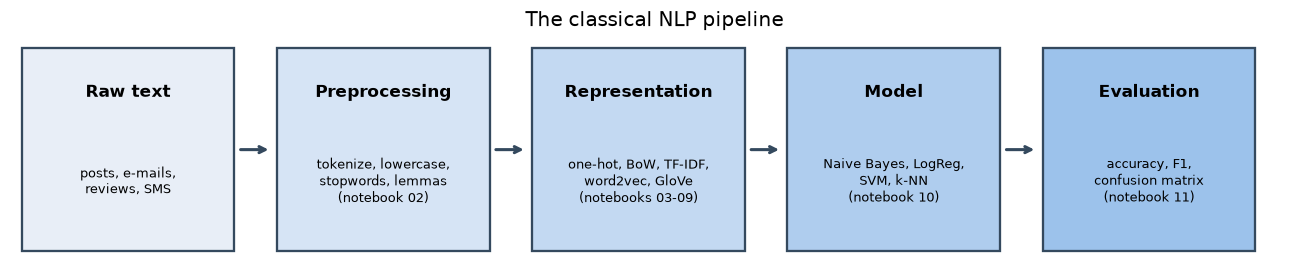

In [3]:
stages = [
    ("Raw text", "posts, e-mails,\nreviews, SMS", "#e8eef7"),
    ("Preprocessing", "tokenize, lowercase,\nstopwords, lemmas\n(notebook 02)", "#d6e4f5"),
    ("Representation", "one-hot, BoW, TF-IDF,\nword2vec, GloVe\n(notebooks 03-09)", "#c3d9f2"),
    ("Model", "Naive Bayes, LogReg,\nSVM, k-NN\n(notebook 10)", "#afcdee"),
    ("Evaluation", "accuracy, F1,\nconfusion matrix\n(notebook 11)", "#9cc2eb"),
]
fig, ax = plt.subplots(figsize=(12, 2.6))
for i, (title, sub, color) in enumerate(stages):
    x = i * 2.4
    ax.add_patch(plt.Rectangle((x, 0), 2.0, 1.6, facecolor=color, edgecolor="#34495e", lw=1.5))
    ax.text(x + 1.0, 1.25, title, ha="center", va="center", fontsize=11, weight="bold")
    ax.text(x + 1.0, 0.55, sub, ha="center", va="center", fontsize=8.5)
    if i < len(stages) - 1:
        ax.annotate("", xy=(x + 2.35, 0.8), xytext=(x + 2.03, 0.8),
                    arrowprops=dict(arrowstyle="->", lw=2, color="#34495e"))
ax.set_xlim(-0.1, 12); ax.set_ylim(-0.1, 1.7); ax.axis("off")
ax.set_title("The classical NLP pipeline", fontsize=13)
plt.tight_layout(); plt.savefig(DOCS / "01_nlp_pipeline.png", bbox_inches="tight"); plt.show()

## 4 · Our main corpus: 20 Newsgroups (4 topics)

**20 Newsgroups** is a classic NLP benchmark: about 20,000 posts from Usenet discussion groups
collected in the 1990s. We use four clearly different groups:

- `rec.sport.baseball` — baseball
- `sci.space` — space science and spaceflight
- `comp.graphics` — computer graphics
- `talk.politics.misc` — political discussion

E-mail headers, signatures and quoted replies were removed, so a model has to learn from the body text
itself. The data comes with a standard **train / test** split (by date). It is cached in `data/` —
`nlp_course.load_newsgroups()` reads it into a pandas DataFrame.

In [4]:
df = nlp_course.load_newsgroups()
print(df.shape)
df.head()

(3729, 4)


,doc_id,text,category,subset
0,60159,"\n\n\n\nYes, long before Star Trek. Before Einstein, in fact.\n\nVulcan as a planet inside Mercury was hypothesized...",sci.space,train
1,178372,^^^^^\n\nI'm curious why you think that particular ad...,talk.politics.misc,train
2,60175,Sounds liek what the FED has to do is sign a 50 or more year lease to use\ncertain parts of a space station that is ...,sci.space,train
3,39662,Can someone please give me a couple names of anonymous\nftp sites that cater to graphics. I am looking for info/\ns...,comp.graphics,test
4,61243,"I know it's only wishful thinking, with our current President,\nbut this is from last fall:\n\n ""Is there life o...",sci.space,test


In [5]:
counts = pd.crosstab(df["category"], df["subset"])
counts["total"] = counts.sum(axis=1)
counts

subset,test,train,total
category,,,
comp.graphics,389,584,973
rec.sport.baseball,397,597,994
sci.space,394,593,987
talk.politics.misc,310,465,775


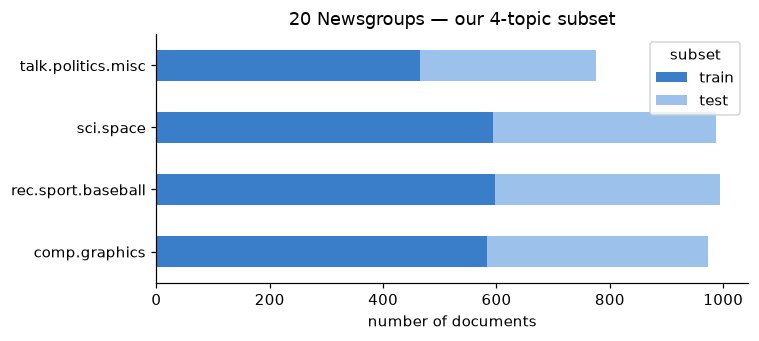

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
counts[["train", "test"]].plot.barh(stacked=True, ax=ax, color=["#3a7dc9", "#9cc2eb"])
ax.set_xlabel("number of documents"); ax.set_ylabel("")
ax.set_title("20 Newsgroups — our 4-topic subset")
plt.tight_layout(); plt.savefig(DOCS / "01_category_counts.png", bbox_inches="tight"); plt.show()

### Reading some documents
Statistics are useful, but **always read your data first**. Here is the beginning of one post from
each category.

In [7]:
train = df[df["subset"] == "train"]
for cat in sorted(train["category"].unique()):
    # first post of this category with a reasonable length
    doc = train[(train["category"] == cat) & (train["text"].str.len().between(300, 1500))].iloc[0]
    print("=" * 90)
    print(f"[{cat}]  doc_id={doc.doc_id}")
    print("-" * 90)
    print(doc.text[:500].strip(), "..." if len(doc.text) > 500 else "")

[comp.graphics]  doc_id=38497
------------------------------------------------------------------------------------------
G'day all,

Can anybody point me at a utility which will read/convert/crop/whatnot/
display HDF image files ? I've had a look at the HDF stuff under NCSA 
and it must take an award for odd directory structure, strange storage
approaches and minimalist documentation :-)

Part of the problem is that I want to look at large (5MB+) HDF files and
crop out a section. Ideally I would like a hdftoppm type of utility, from
which I can then use the PBMplus stuff quite merrily. I can convert the cropped
pa ...
[rec.sport.baseball]  doc_id=102612
------------------------------------------------------------------------------------------
The O's just lost to the Rangers a few minutes ago I was not too happy about
the pitching of Rick Sutcliffe (6 runs in 6 innings, 5 in the 3?) This puts
me in remembering the 1990 O's season. After '89 we didn't do much over
winter and we wound up

Notice how messy real text is: abbreviations, numbers, odd punctuation, line breaks, typos.
Notebook 02 is all about cleaning this up.

## 5 · How long are documents?
A first, simple measurement: the number of whitespace-separated tokens per document.

In [8]:
df["n_tokens"] = df["text"].str.split().str.len()
df.groupby("category")["n_tokens"].describe()[["count", "mean", "50%", "min", "max"]].round(1)

,count,mean,50%,min,max
category,,,,,
comp.graphics,973.0,196.8,65.0,0.0,9196.0
rec.sport.baseball,994.0,124.9,69.0,0.0,2479.0
sci.space,987.0,189.9,85.0,0.0,9113.0
talk.politics.misc,775.0,282.8,110.0,0.0,7952.0


In [9]:
n_empty = (df["n_tokens"] == 0).sum()
n_short = (df["n_tokens"] < 5).sum()
print(f"Empty documents (0 tokens): {n_empty}")
print(f"Very short documents (< 5 tokens): {n_short}  ({n_short / len(df):.1%} of the corpus)")

Empty documents (0 tokens): 105
Very short documents (< 5 tokens): 148  (4.0% of the corpus)


Some posts are empty: they consisted *only* of headers, a signature or a quoted reply, which were
stripped. Real corpora always contain such noise, and it is good to know how much.

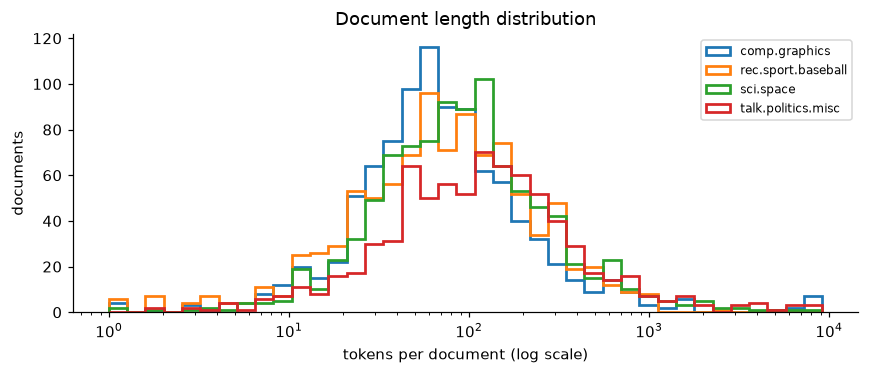

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.logspace(0, np.log10(df["n_tokens"].max() + 1), 40)
for cat, g in df[df["n_tokens"] > 0].groupby("category"):
    ax.hist(g["n_tokens"], bins=bins, histtype="step", lw=1.8, label=cat)
ax.set_xscale("log"); ax.set_xlabel("tokens per document (log scale)"); ax.set_ylabel("documents")
ax.set_title("Document length distribution"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(DOCS / "01_document_lengths.png", bbox_inches="tight"); plt.show()

## 6 · Tokens, types and the vocabulary of a real corpus
Let's count tokens and types over the whole training set, still with the naive `str.split()`
tokenizer.

In [11]:
from collections import Counter

all_tokens = [tok for text in train["text"] for tok in text.split()]
freq = Counter(all_tokens)
print(f"tokens (occurrences): {len(all_tokens):,}")
print(f"types (vocabulary):   {len(freq):,}")
print(f"types seen only once (hapax legomena): {sum(1 for c in freq.values() if c == 1):,}")

tokens (occurrences): 417,855
types (vocabulary):   61,231
types seen only once (hapax legomena): 38,325


In [12]:
pd.DataFrame(freq.most_common(20), columns=["token", "count"]).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
token,the,to,of,a,and,in,is,that,I,for,on,be,you,it,have,are,with,The,this,as
count,18415,10347,8984,8120,7952,5644,5253,4871,4494,3950,2907,2671,2585,2553,2473,2353,2211,2209,2061,1989


The most frequent "words" are `the`, `to`, `of`, `a`… — **function words** that tell us almost
nothing about the topic. We also see that `The` and `the` are counted as different types, and tokens
glued to punctuation (`it.`, `it,`) inflate the vocabulary. These are exactly the problems
preprocessing (notebook 02) solves.

## 7 · Zipf's law
In 1935 George Kingsley Zipf noticed that in any language the frequency of a word is roughly
inversely proportional to its rank: the 2nd most common word appears about half as often as the 1st,
the 3rd about a third as often, and so on:

$$ f(r) \propto \frac{1}{r} $$

On a log–log plot this is a straight line with slope ≈ −1. Let's check our corpus.

fitted slope over the top 5,000 ranks: -0.97


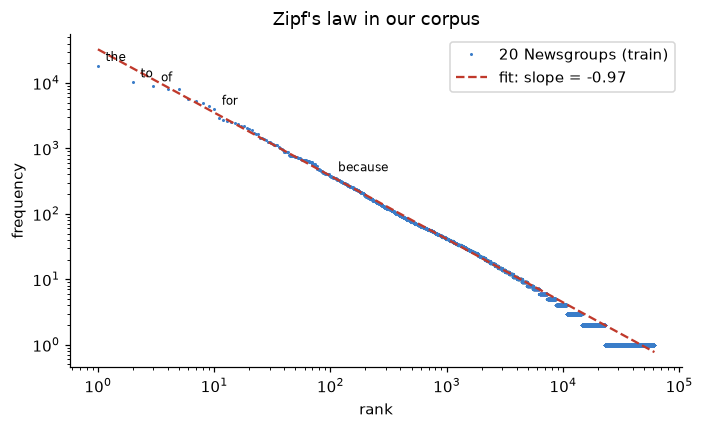

In [13]:
ranked = np.array(sorted(freq.values(), reverse=True))
ranks = np.arange(1, len(ranked) + 1)
slope, intercept = np.polyfit(np.log10(ranks[:5000]), np.log10(ranked[:5000]), 1)
print(f"fitted slope over the top 5,000 ranks: {slope:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.loglog(ranks, ranked, ".", ms=2, color="#3a7dc9", label="20 Newsgroups (train)")
ax.loglog(ranks, 10 ** intercept * ranks ** slope, "--", color="#c0392b", label=f"fit: slope = {slope:.2f}")
for r in [1, 2, 3, 10, 100]:
    ax.annotate(freq.most_common(r)[-1][0], (r, ranked[r - 1]),
                textcoords="offset points", xytext=(5, 3), fontsize=8)
ax.set_xlabel("rank"); ax.set_ylabel("frequency"); ax.set_title("Zipf's law in our corpus"); ax.legend()
plt.tight_layout(); plt.savefig(DOCS / "01_zipf.png", bbox_inches="tight"); plt.show()

In [14]:
top100_share = ranked[:100].sum() / ranked.sum()
print(f"The 100 most frequent types cover {top100_share:.1%} of all tokens,")
print(f"while {sum(1 for c in freq.values() if c == 1) / len(freq):.1%} of the types occur only once.")

The 100 most frequent types cover 38.9% of all tokens,
while 62.6% of the types occur only once.


**Why this matters:** a handful of very frequent words dominate the counts, and a long tail of rare
words blows up the vocabulary. Removing stopwords, normalising word forms (notebook 02) and
down-weighting frequent words with TF-IDF (notebook 04) all respond to Zipf's law.

## 8 · A second corpus: SMS Spam Collection
We will also use 5,574 real SMS messages labelled **ham** (normal) or **spam**. They are short, informal
and full of abbreviations — very different from newsgroup posts.

In [15]:
sms = nlp_course.load_sms()
print(sms["label"].value_counts().to_string())
print(f"\nspam share: {(sms['label'] == 'spam').mean():.1%}")
sms.groupby("label").head(3)

label
ham     4827
spam     747

spam share: 13.4%


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...


In [16]:
sms["n_tokens"] = sms["text"].str.split().str.len()
sms.groupby("label")["n_tokens"].describe()[["mean", "50%", "max"]].round(1)

,mean,50%,max
label,,,
ham,14.3,11.0,171.0
spam,23.9,25.0,35.0


Two things to remember: messages are tiny (a median of 11 words for ham, 25 for spam), and the classes are
**imbalanced** (about 13% spam). Both will matter when we classify text in notebooks 10–11.

## 9 · Where this course goes — and where it stops

| Part | Notebooks | Idea |
|---|---|---|
| Foundations | 01 · 02 | text basics, preprocessing |
| Sparse representations | 03 · 04 · 05 · 06 · 07 | one-hot, Bag-of-Words, TF-IDF, n-grams, similarity, LSA |
| Dense representations | 08 · 09 | word2vec, GloVe |
| Classic machine learning | 10 · 11 · 12 | classification, evaluation, a mini project |

The course **stops at classic machine learning on text**. Recurrent networks, attention and
transformers (BERT, GPT) are out of scope; they are covered step by step in the companion course
[attention-explained](https://github.com/hentablihamza/attention-explained).

## 10 · Exercises
Try each exercise in the empty cell below it before opening the solution.

**Exercise 1.** Which category has the longest *median* document (in whitespace tokens)? And the shortest?

In [17]:
# your code here

<details>
<summary><b>Show solution</b></summary>

```python
med = df.groupby("category")["n_tokens"].median().sort_values()
print(med)
print("longest:", med.idxmax(), "| shortest:", med.idxmin())
```
</details>

In [18]:
med = df.groupby("category")["n_tokens"].median().sort_values()
print(med)
print("longest:", med.idxmax(), "| shortest:", med.idxmin())

category
comp.graphics          65.0
rec.sport.baseball     69.0
sci.space              85.0
talk.politics.misc    110.0
Name: n_tokens, dtype: float64
longest: talk.politics.misc | shortest: comp.graphics


**Exercise 2.** Count tokens and types for the `sci.space` training documents only, after
lowercasing every token. How much smaller is the vocabulary than without lowercasing?

In [19]:
# your code here

<details>
<summary><b>Show solution</b></summary>

```python
space = train[train["category"] == "sci.space"]["text"]
toks = [t for text in space for t in text.split()]
print("tokens:", len(toks))
print("types (original case):", len(set(toks)))
print("types (lowercased):   ", len({t.lower() for t in toks}))
print(f"reduction: {1 - len({t.lower() for t in toks}) / len(set(toks)):.1%}")
```
</details>

In [20]:
space = train[train["category"] == "sci.space"]["text"]
toks = [t for text in space for t in text.split()]
print("tokens:", len(toks))
print("types (original case):", len(set(toks)))
print("types (lowercased):   ", len({t.lower() for t in toks}))
print(f"reduction: {1 - len({t.lower() for t in toks}) / len(set(toks)):.1%}")

tokens: 119975
types (original case): 26147
types (lowercased):    23177
reduction: 11.4%


**Exercise 3.** List the 15 most frequent tokens in the **spam** SMS messages. Do any of them
already look like good spam signals?

In [21]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Besides stopwords, words like `call`, `your`, `free`, `ur` and `txt` stand out — a hint that even simple word counts carry a lot of signal.

```python
spam_freq = Counter(t.lower() for text in sms.loc[sms["label"] == "spam", "text"] for t in text.split())
pd.DataFrame(spam_freq.most_common(15), columns=["token", "count"]).T
```
</details>

In [22]:
spam_freq = Counter(t.lower() for text in sms.loc[sms["label"] == "spam", "text"] for t in text.split())
pd.DataFrame(spam_freq.most_common(15), columns=["token", "count"]).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
token,to,a,call,your,you,the,for,or,free,2,is,ur,on,txt,have
count,685,375,342,263,252,204,201,188,180,169,152,144,142,136,135


## Summary
- NLP is about turning text into numbers that algorithms can use, without losing meaning.
- A corpus is made of documents; documents are made of tokens; distinct tokens are types; all types form the vocabulary.
- The classical pipeline is **raw text → preprocessing → representation → model → evaluation**.
- Real text is messy and word frequencies follow Zipf's law: a few function words dominate, and a long tail of rare words inflates the vocabulary.

**Next:** [02 · Text preprocessing](02_text_preprocessing.ipynb) — tokenization, stopwords, stemming,
lemmatization and regular expressions.